In [2]:
# Maximiliano Alonso Zamarin Luco 22.246.438-2
mi_numero=5678
import numpy as np
import matplotlib.pyplot as plt

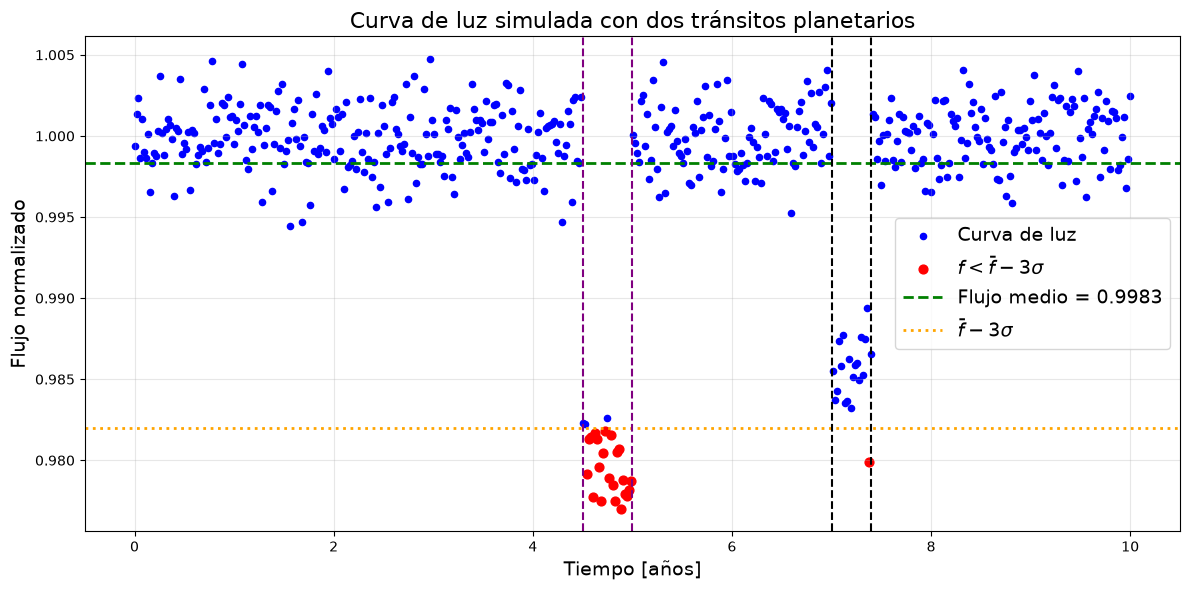

In [6]:
t = np.linspace(0,10,500) #arreglo temporal
flujo= np.ones_like(t) #flujo normalizado de la estrella. Igual a 1 en todos los tiempos
rng = np.random.default_rng(mi_numero)

#Primer transito 
flujo[(t >= 4.5) & (t <= 5.0)] -= 0.02

#Segundo transito
flujo[(t >= 7) & (t <= 7.4)] -= 0.015

#Ruido gaussiano con desviación estándar 0.002
flujo += rng.normal(0, 0.002, size=t.shape)

def curva_luz(t,flujo):
    #Datos necesarios para la funcion
    f = np.mean(flujo)
    sigma = np.std(flujo)
    umbral = f - 3*sigma

    #Puntos para transito
    transito = flujo < umbral
    plt.figure(figsize=(12,6))

    #Todos los puntos
    plt.scatter(t, flujo, color='blue', s=20, label='Curva de luz')
    
    #Puntos bajo el umbral
    plt.scatter(t[transito], flujo[transito], color='red', marker='o', s=40, label=r'$f < \bar{f} - 3\sigma$')

    #Flujo medio del flujo 
    plt.axhline(f, color='green', linestyle='--', linewidth=2, label=f'Flujo medio = {f:.4f}')

    #Umbral de deteccion
    plt.axhline(umbral, color='orange', linestyle=':', linewidth=2, label=r'$\bar{f}-3\sigma$')
    
    #Primer tránsito
    plt.axvline(4.5, color='purple', linestyle='--')
    plt.axvline(5.0, color='purple', linestyle='--')

    #Segundo tránsito
    plt.axvline(7.0, color='black', linestyle='--')
    plt.axvline(7.4, color='black', linestyle='--')

    #Grafico
    plt.xlabel('Tiempo [años]', fontsize=14)
    plt.ylabel('Flujo normalizado', fontsize=14)
    plt.title('Curva de luz simulada con dos tránsitos planetarios', fontsize=16)
    plt.legend(fontsize=14)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

#Llamar a la funcion con los parametros antes definidos
curva_luz(t, flujo)


Posiciones x0: [4.22826826 1.70890139 1.73523094 0.30388095 2.98787664]
Posiciones y0: [ 2.78318666 -3.1572698   0.05900075  2.17295707  0.66855985]


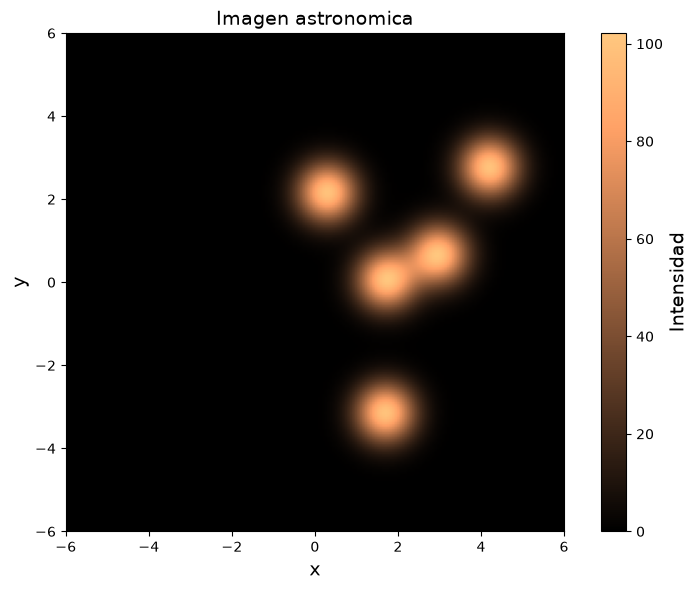

Distancias entre pares de estrellas:
[np.float64(6.452614380845223), np.float64(3.6927528888180823), np.float64(3.971548294713522), np.float64(2.4515745780935125), np.float64(3.216378325884265), np.float64(5.512295433902706), np.float64(4.033949701393019), np.float64(2.5529539939752888), np.float64(1.3930841791152522), np.float64(3.0768561601499673)]


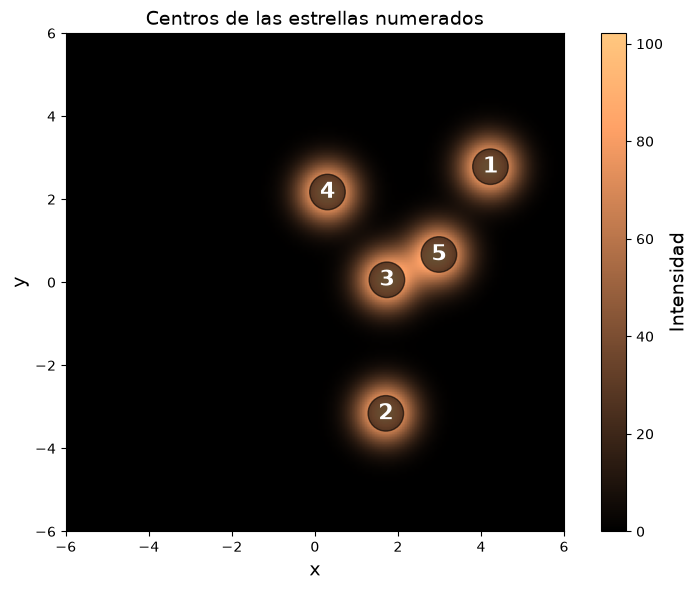

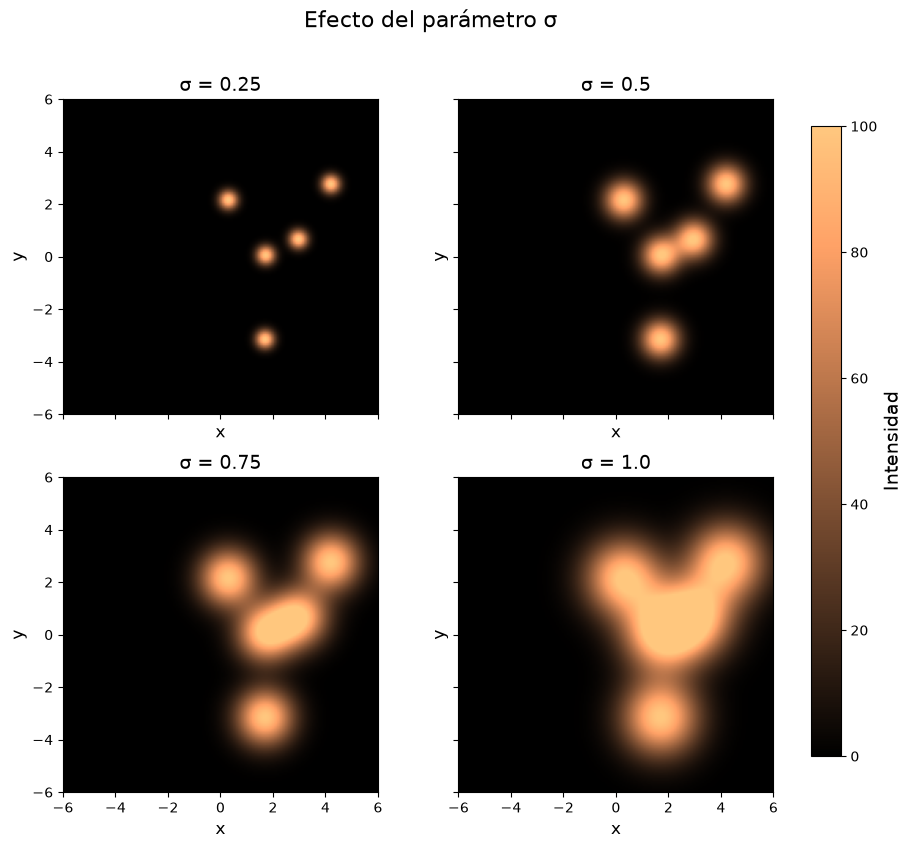

In [5]:

#A GENERAR LA IMAGEN---

#Constantes
Nestrellas = 5 #Estrellas a simular
I0 = 100
sigma = 0.5
rng = np.random.default_rng(mi_numero)

#Rango donde las estrellas pueden aparecer aleatoriament
x0 = rng.uniform(-5, 5, Nestrellas)
y0 = rng.uniform(-5, 5, Nestrellas)

print("Posiciones x0:", x0)
print("Posiciones y0:", y0)

#Grilla donde se calculan los puntos
x= np.linspace(-6,6,200)
y= np.linspace(-6,6,200)
X, Y = np.meshgrid(x,y) #Crea la matriz


#Intensidad total
I= np.zeros_like(X) #Matrizes de ceros
for i in range(Nestrellas):
    #Funcion gaussiana bidimensional
    I += I0* np.exp( -((X - x0[i])**2 + (Y -y0[i])**2)/(2*sigma**2))

#Grafico
fig, ax = plt.subplots(figsize=(8,6))
im = ax.imshow(I, extent=[-6, 6, -6, 6], origin="lower", cmap="copper")
ax.set_xlabel("x", fontsize=14)
ax.set_ylabel("y", fontsize=14)
ax.set_title("Imagen astronomica", fontsize=14)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Intensidad', fontsize=14)
plt.tight_layout()
plt.show()

#B DISTANCIA ENTRE LAS ESTRELLAS

#Funcion que calcula la distancia en todos los pares y luego devuelve su diccionario
def distancias(x0,y0):
    N= len(x0)
    distancias=[]

    for i in range(N):
        for j in range(i+1, N): #El i+1 es para evitar duplicados y al calculo en si mismo (No lo sabia antes lo aprendi ahora)
            d = np.sqrt( (x0[i] - x0[j])**2 + (y0[i] - y0[j])**2 )
            distancias.append(d)
    return distancias
dists = distancias(x0, y0)
print("Distancias entre pares de estrellas:")
print(dists)

#C IMAGEN CON LOS CENTROS NUMERADOS

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(I, extent=[-6, 6, -6, 6], origin='lower', cmap='copper')
ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('y', fontsize=14)
ax.set_title('Centros de las estrellas numerados', fontsize=14)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Intensidad', fontsize=14)

# Incorporar los números
for i in range(Nestrellas):
    ax.text(x0[i], y0[i], str(i+1), color='white', fontsize=16,
            ha='center', va='center', fontweight='bold',
            bbox=dict(boxstyle='circle', facecolor='black', alpha=0.6))

plt.tight_layout()
plt.savefig('imagen_estrellas_c.png', dpi=150) #Para poder guardar la figura
plt.show()

#D Distintos sigmas
sigmas = [0.25, 0.5, 0.75, 1.0] #Los defino manualmente 

fig, axes = plt.subplots(2, 2, figsize=(10, 9), sharex=True, sharey=True)

for ax, sig in zip(axes.flat, sigmas):
    I_temp = np.zeros_like(X)  #Se usa una nueva matriz de intnsidad
    for i in range(Nestrellas):
        I_temp += I0 * np.exp( -((X - x0[i])**2 + (Y - y0[i])**2) / (2 * sig**2) )
    
    im = ax.imshow(I_temp, extent=[-6, 6, -6, 6], origin='lower',
                   cmap='copper', vmin=0, vmax=I0)
    ax.set_title(f'σ = {sig}', fontsize=14)
    ax.set_xlabel('x', fontsize=12)
    ax.set_ylabel('y', fontsize=12)

# Colorbar unica (para compartir el color)
fig.subplots_adjust(right=0.85)
cbar_ax = fig.add_axes([0.88, 0.15, 0.03, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label('Intensidad', fontsize=14)

plt.suptitle('Efecto del parámetro σ', fontsize=16)
plt.savefig('imagen_estrellas_d.png', dpi=150, bbox_inches='tight')
plt.show()
